In [1]:
from base.environment import Environment
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Graphs Thesis

In [6]:
SIMU = Environment(N=10, Lambda=0, p = 0.5, seed = 1)

In [3]:
from datetime import datetime

import networkx as nx
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

def graph(self, save = False, selected_node=None):
    COLOR_PATIENT = "#4A90E2"
    COLOR_IMPATIENT = "#D9534F"
    COLOR_EDGE = "#BDC3C7"

    patient_nodes = []
    impatient_nodes = []

    for node in self.G.nodes():
        agent = self.agents_by_node[node]

        if agent.is_patient:
            patient_nodes.append(node)
        else:
            impatient_nodes.append(node)


    if self.network_type == "grid":
        self.pos = {node: node for node in self.G.nodes()}
    elif self.network_type == "clustered":
        self.pos = nx.spring_layout(self.G, k=0.15, iterations=100, seed=42)
    else:
        self.pos = nx.spring_layout(self.G, seed=42)

    fig, ax = plt.subplots(figsize=(10, 7), dpi=300)
    
    nx.draw_networkx_edges(self.G, self.pos, ax=ax, edge_color=COLOR_EDGE, style="dashed", width=1.5, alpha=0.8)
    nx.draw_networkx_nodes(self.G, self.pos, ax=ax, nodelist=patient_nodes, node_color=COLOR_PATIENT, edgecolors="#2C3E50", node_size=380, linewidths=1.2)
    nx.draw_networkx_nodes(self.G, self.pos, ax=ax, nodelist=impatient_nodes, node_color=COLOR_IMPATIENT, edgecolors="#5B1208", node_size=380, linewidths=1.2)

    if self.network_type == "grid":
        labels = {node: i for i, node in enumerate(self.G.nodes())}
        nx.draw_networkx_labels(self.G, self.pos, ax=ax, labels=labels, font_size=11, font_color="white", font_weight="bold")
    else:
        nx.draw_networkx_labels(self.G, self.pos, ax=ax, font_size=11, font_color="white", font_weight="bold")

    
    ax.set_title("Depositor Interaction Network Topology", loc="left", fontweight="bold", pad=20, fontsize=18)
    if self.network_type == 'clustered':
        ax.text(0, 1, rf"{self.network_type.capitalize()} Network ($C = $ {self.number_of_clusters}, $p_i =$ {self.p_inside}, $p_o =$ {self.p_outside})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
    elif self.network_type == 'grid':
        ax.text(0, 1, rf"{self.network_type.capitalize()} Network ({int(self.N**0.5)}x{int(self.N**0.5)})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
    elif self.network_type == 'Watts-Strogatz':
        ax.text(0, 1, rf"{self.network_type.capitalize()} Network ($p = $ {self.p}, $k = $ {self.mean_degree_par})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
    elif self.network_type == 'Barabasi-Albert':
        ax.text(0, 1, rf"{self.network_type.capitalize()} Network ($m = $ {self.edges_par})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
    else:
        ax.text(0, 1, rf"{self.network_type.capitalize()} Network ($p = $ {self.p})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")

    if selected_node is not None:
        nx.draw_networkx_nodes(self.G, self.pos, ax=ax, nodelist=[selected_node], node_color= COLOR_IMPATIENT, edgecolors="black", node_size=500, linewidths=2.5)

        # Conexiones incidentes al nodo seleccionado
        selected_edges = [(u, v) for u, v in self.G.edges() if u == selected_node or v == selected_node]

        nx.draw_networkx_edges(self.G, self.pos, ax=ax, edgelist=selected_edges, edge_color="#2C3E50", style="solid", width=2.8, alpha=1.0)

    ax.axis("off")
    ax.set_aspect("equal")

    legend_handles = [mpatches.Patch(color=COLOR_PATIENT, ec="#2C3E50", label=r"Depositors"), mlines.Line2D([], [], color=COLOR_EDGE, lw=1.8, ls="--", label=r"Interaction Channels ($g_{ij}$)"), mpatches.Patch(color=COLOR_IMPATIENT, ec="#5B1208", label=r"Selected Depositor"), mlines.Line2D([], [], color='#2C3E50', lw=2.8, label=r"Local Neighborhood ($\mathcal {N} _{4}$)")]

    ax.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=False, fontsize=13, labelspacing=1.2, handlelength=2.2, handleheight=1.5)
    
    plt.tight_layout()
    if save:
        plt.savefig(f'outputs/MODEL/FIG{datetime.now().strftime("%d-%m-%y.%H.%M.%S")}.png', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


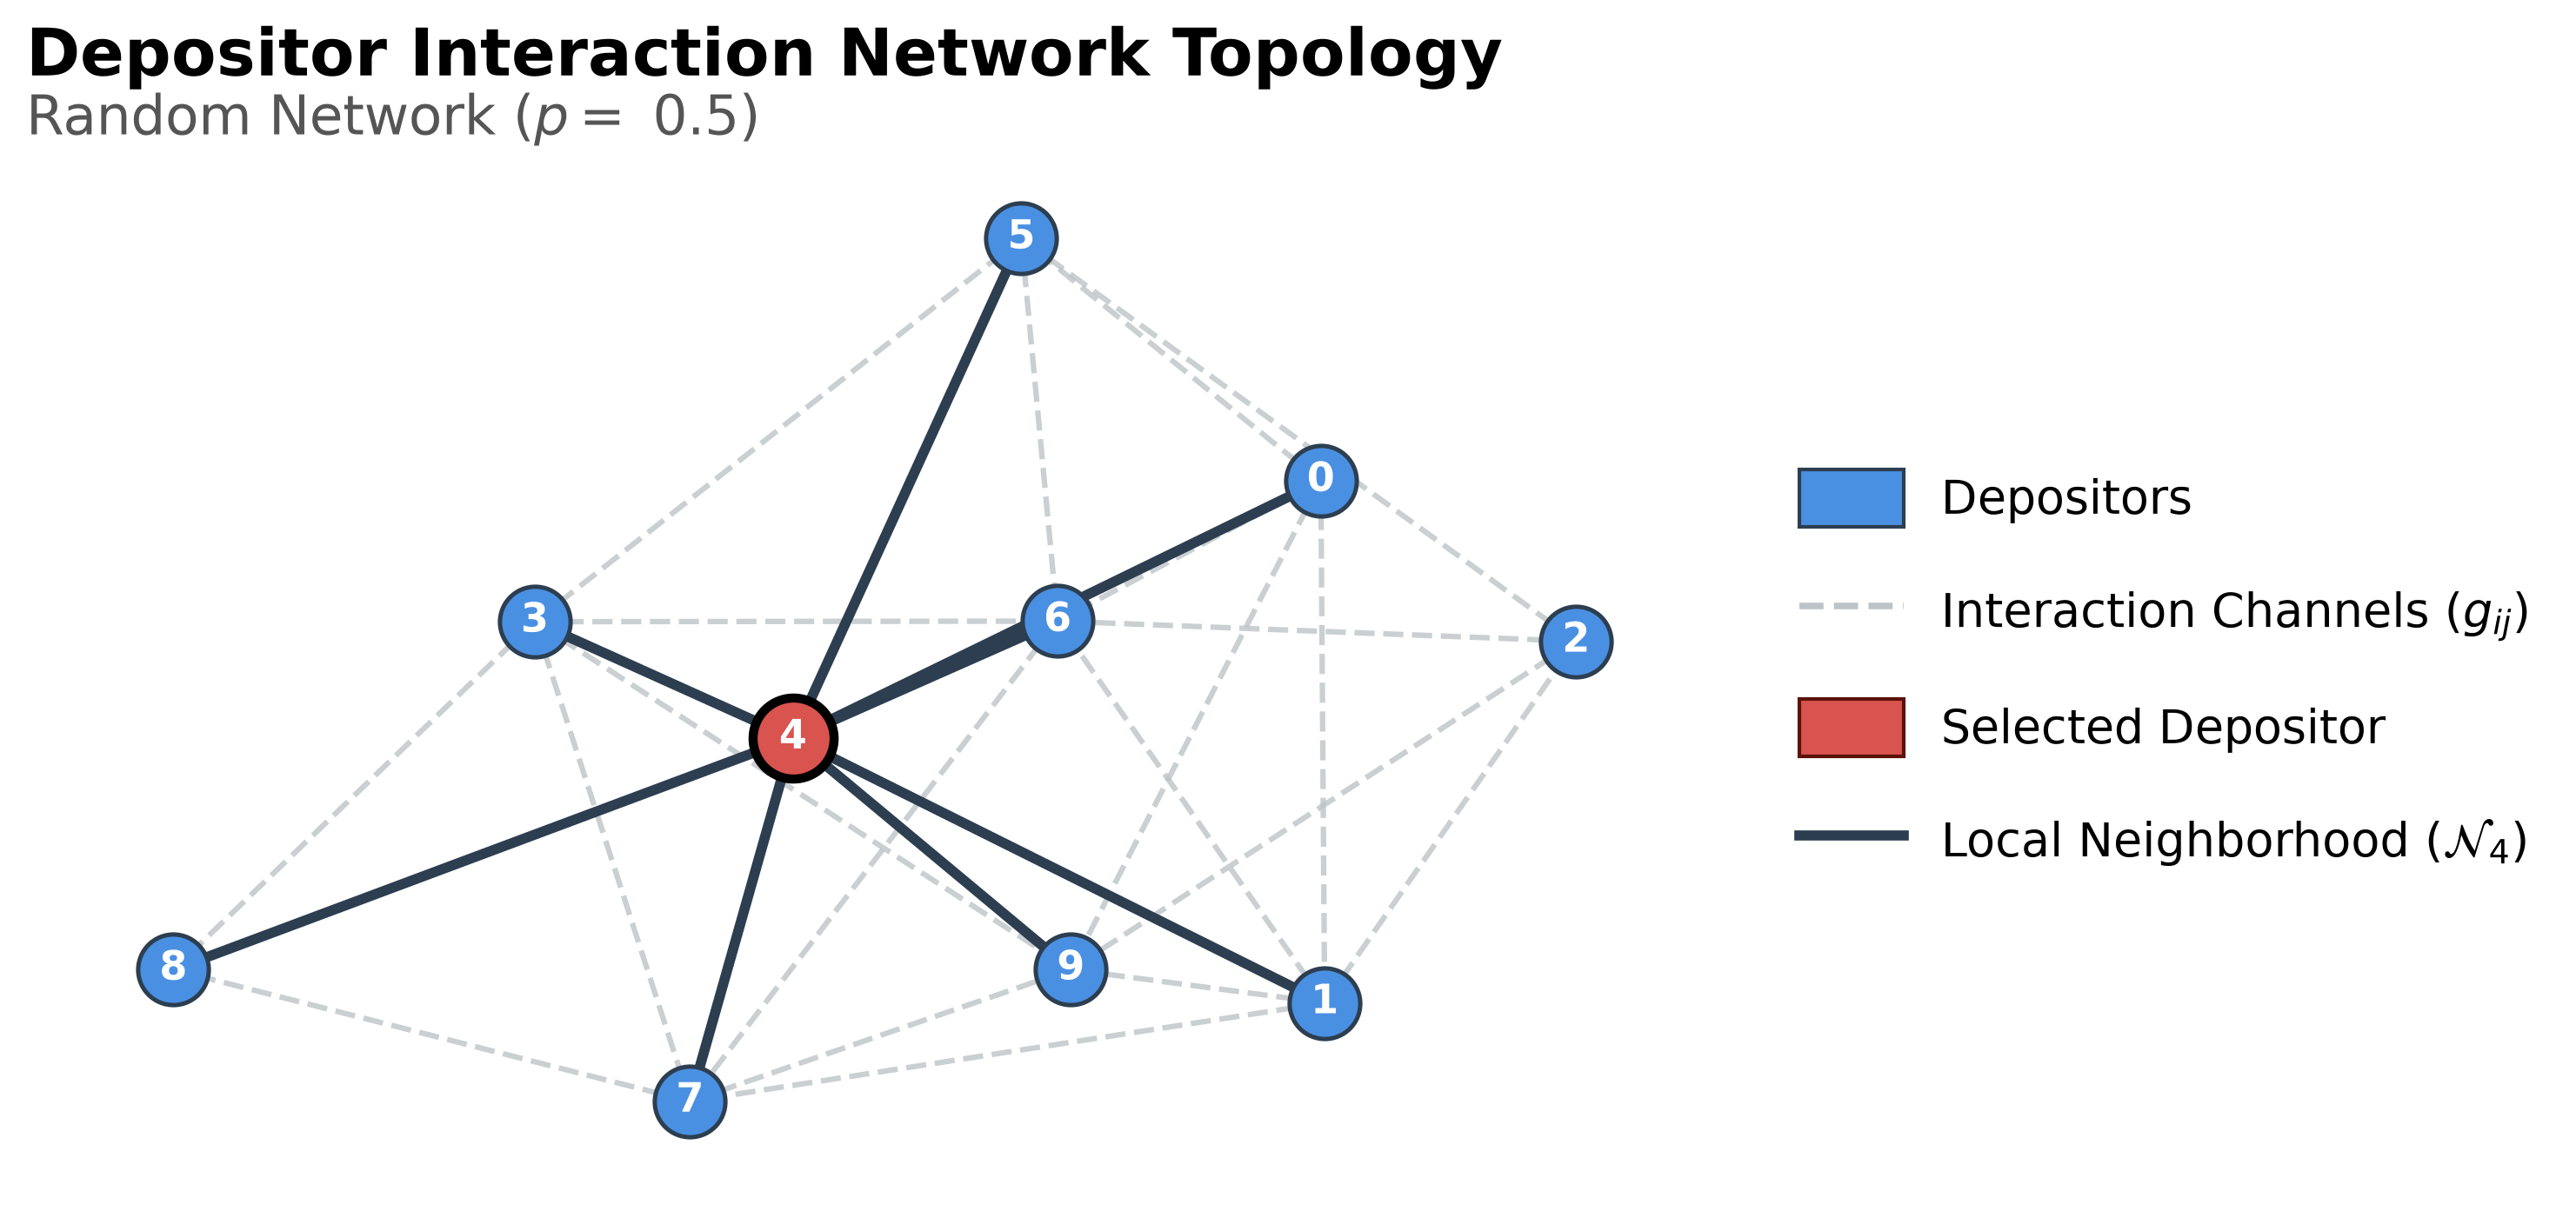

In [7]:
graph(SIMU.network, selected_node=4)

In [8]:
SIMU.network.average_path_length()

1.4